<div dir="rtl">

# חיפוש הסיגנל – LifeGuard
### האם פשיעה ב־2024 מנבאת אילו אזורים יהיו בסיכון גבוה ב־2025?

המחברת מבצעת את `notebook/eda_plan.md` סעיף אחרי סעיף. מתחת לכל גרף יש משפט אחד שמסביר מה רואים בו, ובסוף יש משפט מסכם על הסיגנל.

**הנתונים:** `research/datasets/crime_by_stat_area_summary.csv` (הקובץ הגולמי) – תיקי משטרה לפי אזור סטטיסטי ב־10 ערים, 2024–2025.

**למה 2024 מול 2025, כשאנחנו כבר ב־2026?** אלה שתי השנים המלאות האחרונות שיש עליהן נתונים. בודקים את השיטה על שנה שהתשובה שלה כבר ידועה (מנבאים את 2025 מתוך 2024 ומשווים לתוצאות האמיתיות), כדי לדעת כמה אפשר לסמוך עליה כשהאפליקציה מנבאת את 2026 מתוך 2025.

</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.family': 'Arial'})
TEAL, ORANGE, GREY = '#1f8a99', '#e8702a', '#9aa5ab'


def he(text):
    # Hebrew text for charts. matplotlib 3.10+ orders right-to-left text itself;
    # older versions need the python-bidi package to reorder it.
    text = str(text)
    if tuple(int(p) for p in matplotlib.__version__.split('.')[:2]) < (3, 10):
        from bidi.algorithm import get_display
        return get_display(text)
    return text


# Hebrew names for the columns, used in tables and charts
HE = {'pop': 'אוכלוסייה', 'cases_2024': 'תיקים 2024', 'cases_2025': 'תיקים 2025',
      'rate_2024': 'שיעור לאלף 2024', 'rate_2025': 'שיעור לאלף 2025',
      'ratio_2024': 'יחס לחציון 2024', 'ratio_2025': 'יחס לחציון 2025',
      'is_visitor_area': 'אזור מבקרים', 'is_small_pop': 'אוכלוסייה קטנה',
      'high_risk_2025': 'סיכון גבוה 2025', 'city': 'עיר', 'unit': 'קוד אזור',
      'area_name': 'שם האזור', 'cases_total': 'סה"כ תיקים', 'status': 'סטטוס'}

raw = pd.read_csv('../research/datasets/crime_by_stat_area_summary.csv')
print('שורות:', raw.shape[0], '| עמודות:', raw.shape[1])
raw.head(3)

שורות: 1126 | עמודות: 19


,yeshuv,yeshuv_name,unit,area_name,pop,cases_total,cases_2024,cases_2025,cases_mean_annual,rate_per_1000,city_median_rate,ratio_city_median,category_default,category_with_around_median,ratio_national_median,category_vs_national_median,status,flags,pop_join
0,70,אשדוד,70:111+112+123+124,אזור תעשייה 3 + אזור התעשייה הקלה אזור התעשייה...,4090.0,1397,685,712,698.5,170.782,26.677,6.402,חריג מאוד,חריג מאוד,7.319,חריג מאוד,ok,high_ratio_check_land_use;visitor_traffic_name...,census2022_by_code_unverified_geography
1,70,אשדוד,70:312,"הקריה-מע""ר (צפון)",1570.0,403,220,183,201.5,128.344,26.677,4.811,חריג מאוד,חריג מאוד,5.500,חריג מאוד,ok,small_population;high_ratio_check_land_use,census2022_by_code_unverified_geography
2,70,אשדוד,70:133,רובע ב' (צפון),4500.0,808,409,399,404.0,89.778,26.677,3.365,חריג מאוד,חריג מאוד,3.848,חריג מאוד,ok,high_ratio_check_land_use,census2022_by_code_unverified_geography


<div dir="rtl">

## 1. השאלה ועמודת התשובה

</div>

<div dir="rtl">

**עמודת התשובה – "סיכון גבוה 2025"** (`high_risk_2025`): האם שיעור התיקים לאלף תושבים ב־2025 הוא **פי 2 או יותר מהחציון של אותה עיר** ב־2025.
העמודה לא קיימת בקובץ, ולכן נחשב אותה בסעיף 3 אחרי ניקוי הנתונים. כל התכונות יחושבו **מ־2024 בלבד**.

</div>

<div dir="rtl">

## 2. טבלת עמודות

</div>

In [2]:
DESC = {'yeshuv': 'קוד יישוב', 'yeshuv_name': 'שם העיר', 'unit': 'קוד האזור הסטטיסטי', 'area_name': 'שם השכונה/האזור',
        'pop': 'מספר תושבים (מפקד 2022)', 'cases_2024': 'תיקי משטרה 2024', 'cases_2025': 'תיקי משטרה 2025',
        'cases_total': 'סכום שתי השנים', 'cases_mean_annual': 'ממוצע שנתי', 'rate_per_1000': 'תיקים לאלף, ממוצע שתי השנים',
        'city_median_rate': 'חציון עירוני, שתי השנים', 'ratio_city_median': 'יחס לחציון העירוני',
        'category_default': 'קטגוריית סיכון', 'category_with_around_median': 'קטגוריה עם "סביב החציון"',
        'ratio_national_median': 'יחס לחציון הארצי', 'category_vs_national_median': 'קטגוריה מול החציון הארצי',
        'status': 'תקינות השורה', 'flags': 'דגלים', 'pop_join': 'שיטת חיבור האוכלוסייה'}
TYPE = {'yeshuv': 'מזהה', 'yeshuv_name': 'קטגוריה', 'unit': 'מזהה', 'area_name': 'טקסט', 'pop': 'מספר',
        'cases_2024': 'מספר', 'cases_2025': 'מספר', 'cases_total': 'מספר', 'cases_mean_annual': 'מספר',
        'rate_per_1000': 'מספר', 'city_median_rate': 'מספר', 'ratio_city_median': 'מספר', 'category_default': 'קטגוריה',
        'category_with_around_median': 'קטגוריה', 'ratio_national_median': 'מספר',
        'category_vs_national_median': 'קטגוריה', 'status': 'קטגוריה', 'flags': 'רשימת תגיות', 'pop_join': 'קטגוריה'}
KNOWN = {'yeshuv': 'כן', 'yeshuv_name': 'כן', 'unit': 'כן', 'area_name': 'כן', 'pop': 'כן', 'cases_2024': 'כן',
         'cases_2025': 'לא – זה העתיד', 'cases_total': 'לא – דליפה', 'cases_mean_annual': 'לא – דליפה',
         'rate_per_1000': 'לא – דליפה', 'city_median_rate': 'לא – דליפה', 'ratio_city_median': 'לא – דליפה',
         'category_default': 'לא – דליפה', 'category_with_around_median': 'לא – דליפה',
         'ratio_national_median': 'לא – דליפה', 'category_vs_national_median': 'לא – דליפה',
         'status': 'כן', 'flags': 'חלקית', 'pop_join': 'כן'}

cols = pd.DataFrame({
    'מה היא': raw.columns.map(DESC),
    'סוג': raw.columns.map(TYPE),
    'ערכים חסרים': raw.isna().sum().values,
    'ערכים שונים': raw.nunique().values,
    'ידועה בזמן החיזוי?': raw.columns.map(KNOWN),
}, index=pd.Index(raw.columns, name='עמודה'))
cols.style.apply(lambda r: ['background-color:#fde3d3' if str(r['ידועה בזמן החיזוי?']).startswith('לא') else '' for _ in r], axis=1)

,מה היא,סוג,ערכים חסרים,ערכים שונים,ידועה בזמן החיזוי?
עמודה,,,,,
yeshuv,קוד יישוב,מזהה,0,10,כן
yeshuv_name,שם העיר,קטגוריה,0,10,כן
unit,קוד האזור הסטטיסטי,מזהה,0,1126,כן
area_name,שם השכונה/האזור,טקסט,346,771,כן
pop,מספר תושבים (מפקד 2022),מספר,249,441,כן
cases_total,סכום שתי השנים,מספר,0,376,לא – דליפה
cases_2024,תיקי משטרה 2024,מספר,0,263,כן
cases_2025,תיקי משטרה 2025,מספר,0,258,לא – זה העתיד
cases_mean_annual,ממוצע שנתי,מספר,0,376,לא – דליפה


<div dir="rtl">

**מסקנה:** 10 מתוך 19 העמודות (מסומנות בכתום) מחושבות משתי השנים יחד, ולכן הן מכילות את 2025, כלומר את התשובה. **הן לא ייכנסו לניתוח.**

</div>

<div dir="rtl">

## 3. בדיקות איכות: חסר, כפול, שגוי

</div>

<div dir="rtl">

### 3א. ערכים חסרים

</div>

In [3]:
STATUS_HE = {'ok': 'תקין', 'no_police_records': 'אין נתוני משטרה', 'no_census_match': 'אין נתוני אוכלוסייה',
             'pop_below_min': 'פחות מ־1,000 תושבים'}
status = raw['status'].map(STATUS_HE).value_counts().rename_axis('סטטוס').to_frame('מספר אזורים')
status['אחוז'] = (status['מספר אזורים'] / len(raw) * 100).round(1)
display(status)

npr = raw[raw.status == 'no_police_records']
print('אזורים בלי נתוני משטרה:', len(npr), '| סה"כ תיקים בהם:', npr.cases_total.sum(),
      '| טווח אוכלוסייה:', int(npr['pop'].min()), '-', int(npr['pop'].max()))

,מספר אזורים,אחוז
סטטוס,,
תקין,530,47.1
אין נתוני משטרה,322,28.6
אין נתוני אוכלוסייה,249,22.1
"פחות מ־1,000 תושבים",25,2.2


אזורים בלי נתוני משטרה: 322 | סה"כ תיקים בהם: 0 | טווח אוכלוסייה: 1010 - 51180


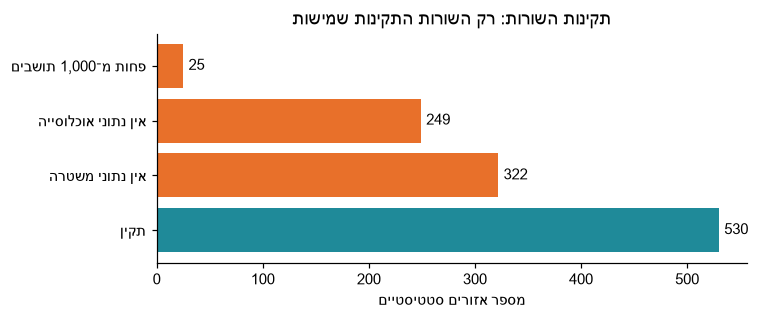

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
s = status['מספר אזורים']
ax.barh([he(i) for i in s.index], s.values, color=[TEAL if i == 'תקין' else ORANGE for i in s.index])
for i, v in enumerate(s.values):
    ax.text(v + 5, i, str(v), va='center')
ax.set_xlabel(he('מספר אזורים סטטיסטיים')); ax.set_title(he('תקינות השורות: רק השורות התקינות שמישות'))
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה רואים:** רק 530 מתוך 1,126 אזורים (47%) שמישים. ב־322 אזורים יש בדיוק 0 תיקים למרות אלפי תושבים. **זה אפס שהוא בעצם ערך חסר** (האזור לא שויך בנתוני המשטרה), ולכן מסירים את השורות האלה ולא מסמנים אותן כ"בטוחות".

</div>

<div dir="rtl">

### 3ב. כפילויות

</div>

In [5]:
print('שורות כפולות לגמרי:', raw.duplicated().sum())
print('קודי אזור שחוזרים פעמיים:', raw['unit'].duplicated().sum())
sub = raw['unit'].str.split(':').str[1].str.split('+').explode()
key = raw['yeshuv'].astype(str).loc[sub.index] + ':' + sub
dup_sub = key[key.duplicated(keep=False)]
print('תתי־אזורים שמופיעים פעמיים:', list(dup_sub.unique()))
raw.loc[dup_sub.index.unique(), ['unit', 'area_name', 'pop', 'cases_total', 'status']].rename(columns=HE)

שורות כפולות לגמרי: 0
קודי אזור שחוזרים פעמיים: 0
תתי־אזורים שמופיעים פעמיים: ['3000:2312']


,קוד אזור,שם האזור,אוכלוסייה,"סה""כ תיקים",סטטוס
104,3000:2311+2312+2312,עיסוויה + א-טור ומורדות הר הזיתים + א-טור ומור...,20450.0,1381,ok


<div dir="rtl">

**מסקנה:** אין שורות כפולות ואין קוד אזור שחוזר פעמיים. נמצאה תקלה אחת: בשורה של עיסוויה וא־טור (ירושלים) תת־האזור 2312 מופיע פעמיים בתוך אותו קוד מאוחד. ייתכן שהאוכלוסייה שלו נספרה פעמיים, ואז השיעור באזור הזה נמוך מהאמת. **החלטה:** משאירים את השורה ומסמנים אותה, כי זו שורה אחת מתוך 530.

</div>

<div dir="rtl">

### 3ג. ערכים שגויים

</div>

In [6]:
print('שורות שבהן סה"כ ≠ 2024 + 2025:', (raw.cases_total != raw.cases_2024 + raw.cases_2025).sum())
print('ספירות שליליות:', (raw[['cases_2024', 'cases_2025']] < 0).sum().sum())
pbm = raw[raw.status == 'pop_below_min']
print('אזורים עם פחות מ־1,000 תושבים:', len(pbm), '| טווח אוכלוסייה:', int(pbm['pop'].min()), '-', int(pbm['pop'].max()))

שורות שבהן סה"כ ≠ 2024 + 2025: 0
ספירות שליליות: 0
אזורים עם פחות מ־1,000 תושבים: 25 | טווח אוכלוסייה: 290 - 980


<div dir="rtl">

**מסקנה:** הסכומים עקביים ואין ערכים שליליים. 25 אזורים עם פחות מ־1,000 תושבים מוסרים, כי בהם תיק אחד מזיז את השיעור יותר מדי.

</div>

<div dir="rtl">

### 3ד. ניקוי וחישוב התכונות והתשובה

</div>

In [7]:
df = raw[raw.status == 'ok'].copy()
df['city'] = df['yeshuv_name']

# Features: 2024 only
df['rate_2024'] = df.cases_2024 / df['pop'] * 1000
df['city_median_2024'] = df.groupby('city').rate_2024.transform('median')
df['ratio_2024'] = df.rate_2024 / df.city_median_2024
flags = df['flags'].fillna('')
df['is_visitor_area'] = flags.str.contains('visitor_traffic').astype(int)
df['is_small_pop'] = flags.str.contains('small_population').astype(int)

# Answer: 2025
df['rate_2025'] = df.cases_2025 / df['pop'] * 1000
df['ratio_2025'] = df.rate_2025 / df.groupby('city').rate_2025.transform('median')
df['high_risk_2025'] = (df.ratio_2025 >= 2).astype(int)

print('שורות אחרי ניקוי:', len(df))
show = ['city', 'pop', 'cases_2024', 'rate_2024', 'ratio_2024', 'is_visitor_area', 'is_small_pop', 'high_risk_2025']
df[show].head().round(2).rename(columns=HE)

שורות אחרי ניקוי: 530


,עיר,אוכלוסייה,תיקים 2024,שיעור לאלף 2024,יחס לחציון 2024,אזור מבקרים,אוכלוסייה קטנה,סיכון גבוה 2025
0,אשדוד,4090.0,685,167.48,7.28,1,0,1
1,אשדוד,1570.0,220,140.13,6.09,0,1,1
2,אשדוד,4500.0,409,90.89,3.95,0,0,1
3,אשדוד,1770.0,141,79.66,3.46,0,1,1
4,אשדוד,2080.0,149,71.63,3.11,0,0,1


<div dir="rtl">

## 4. התפלגויות

</div>

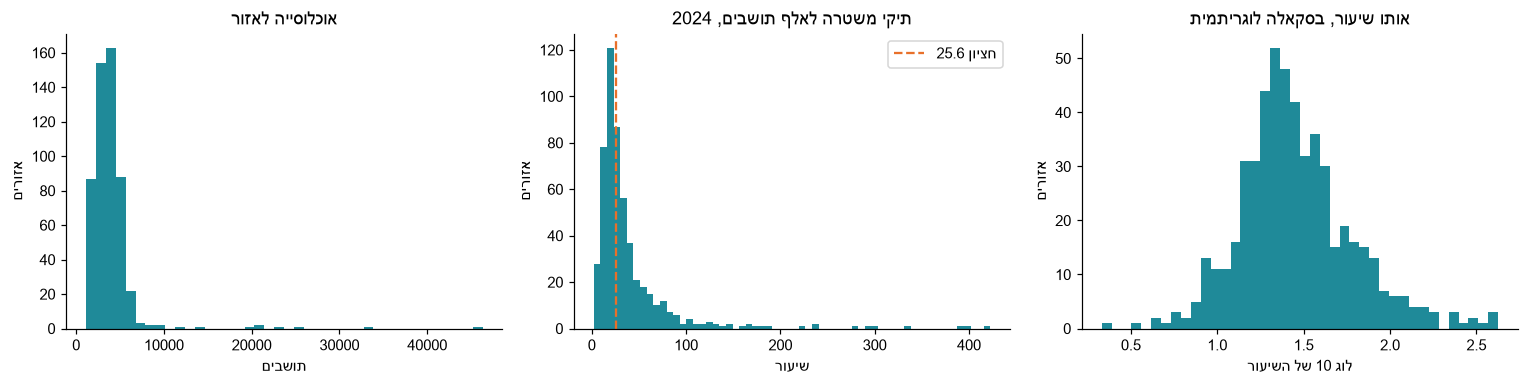

,אוכלוסייה,שיעור לאלף 2024,יחס לחציון 2024
מספר שורות,530.00,530.00,530.00
ממוצע,3923.94,40.00,1.46
סטיית תקן,3189.63,48.17,1.61
מינימום,1120.00,2.14,0.11
רבעון 25%,2632.50,18.13,0.71
חציון,3555.00,25.62,1.00
רבעון 75%,4450.00,41.39,1.49
מקסימום,46300.00,422.63,17.92


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(df['pop'], bins=40, color=TEAL)
axes[0].set_title(he('אוכלוסייה לאזור')); axes[0].set_xlabel(he('תושבים'))
axes[1].hist(df.rate_2024, bins=60, color=TEAL)
axes[1].axvline(df.rate_2024.median(), color=ORANGE, ls='--', label=he(f'חציון {df.rate_2024.median():.1f}'))
axes[1].set_title(he('תיקי משטרה לאלף תושבים, 2024')); axes[1].set_xlabel(he('שיעור')); axes[1].legend()
axes[2].hist(np.log10(df.rate_2024), bins=40, color=TEAL)
axes[2].set_title(he('אותו שיעור, בסקאלה לוגריתמית')); axes[2].set_xlabel(he('לוג 10 של השיעור'))
for a in axes: a.set_ylabel(he('אזורים'))
plt.tight_layout(); plt.show()

stats = df[['pop', 'rate_2024', 'ratio_2024']].describe().round(2).rename(columns=HE)
stats.index = ['מספר שורות', 'ממוצע', 'סטיית תקן', 'מינימום', 'רבעון 25%', 'חציון', 'רבעון 75%', 'מקסימום']
stats

<div dir="rtl">

**מה רואים:** רוב האזורים מונים 2,000–5,000 תושבים, כפי שציפינו. השיעור מוטה חזק לימין: החציון בסביבות 26 לאלף, אבל יש אזורים מעל 400. בסקאלה לוגריתמית ההתפלגות כמעט פעמון, ולכן **עדיף לעבוד עם היחס לחציון או עם לוג, ולא עם השיעור הגולמי.**

</div>

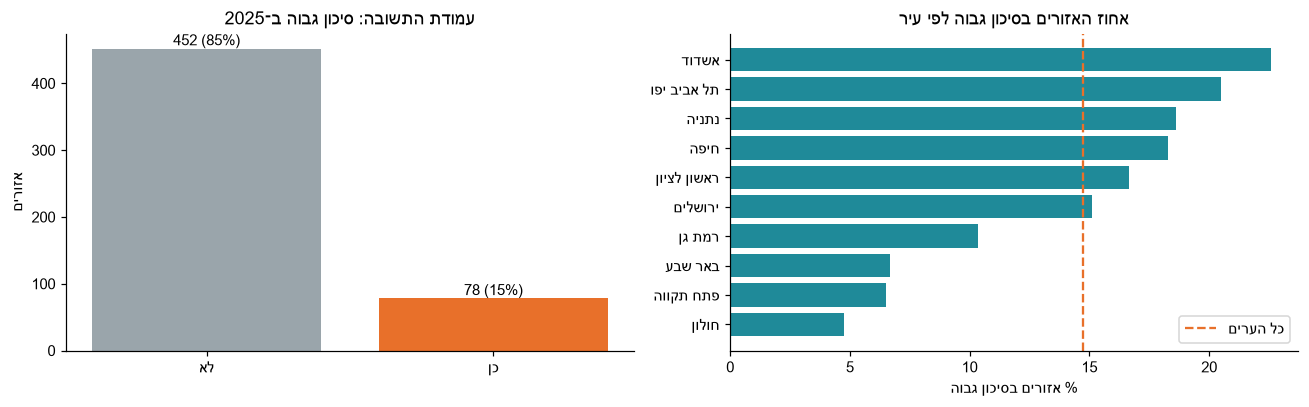

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
counts = df.high_risk_2025.value_counts().sort_index()
axes[0].bar([he('לא'), he('כן')], counts.values, color=[GREY, ORANGE])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, f'{v} ({v / len(df):.0%})', ha='center')
axes[0].set_title(he('עמודת התשובה: סיכון גבוה ב־2025')); axes[0].set_ylabel(he('אזורים'))

by_city = df.groupby('city').high_risk_2025.mean().sort_values()
axes[1].barh([he(c) for c in by_city.index], by_city.values * 100, color=TEAL)
axes[1].axvline(df.high_risk_2025.mean() * 100, color=ORANGE, ls='--', label=he('כל הערים'))
axes[1].set_xlabel(he('% אזורים בסיכון גבוה')); axes[1].set_title(he('אחוז האזורים בסיכון גבוה לפי עיר')); axes[1].legend()
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה רואים:** התשובה לא מאוזנת. רק כ־15% מהאזורים (78) מסומנים "כן", ולכן דיוק לבדו יטעה. אחוז ה"כן" שונה מאוד בין הערים, מכ־5% בחולון ובפתח תקווה ועד מעל 20% באשדוד ובתל אביב. **כלומר, יש ערים שבהן הפשיעה מרוכזת בכמה מוקדים, ויש ערים שבהן היא מפוזרת.**

</div>

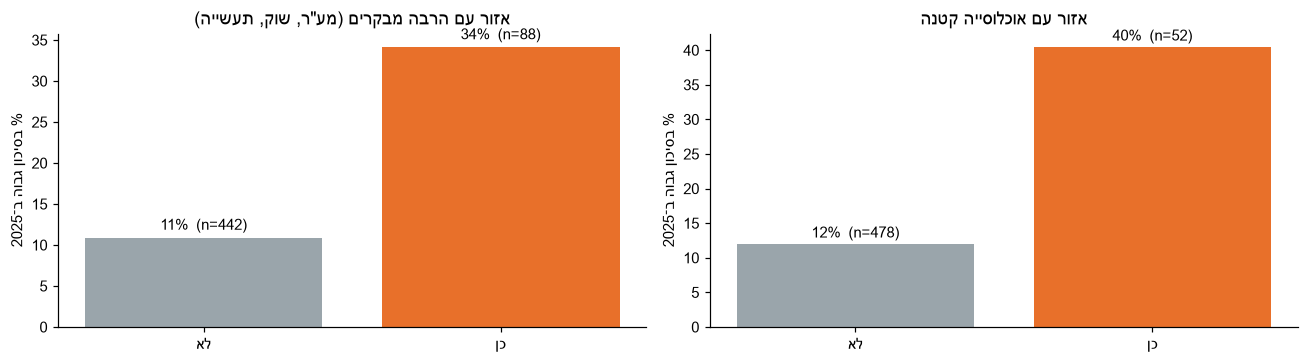

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, col, name in [(axes[0], 'is_visitor_area', 'אזור עם הרבה מבקרים (מע"ר, שוק, תעשייה)'),
                      (axes[1], 'is_small_pop', 'אזור עם אוכלוסייה קטנה')]:
    g = df.groupby(col).high_risk_2025.agg(['mean', 'size'])
    ax.bar([he('לא'), he('כן')], g['mean'] * 100, color=[GREY, ORANGE])
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, m * 100 + 1, f'{m:.0%}  (n={n})', ha='center')
    ax.set_title(he(name)); ax.set_ylabel(he('% בסיכון גבוה ב־2025'))
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה רואים:** באזורים עם הרבה מבקרים, 34% הם בסיכון גבוה, לעומת 11% בשאר. גם באזורים עם אוכלוסייה קטנה הפער דומה (40% מול 12%). **שתי העמודות האלה מוסיפות סיגנל בינוני**, כפי שהשערנו.

</div>

<div dir="rtl">

## 5. הניחוש: אילו עמודות זזות עם התשובה

</div>

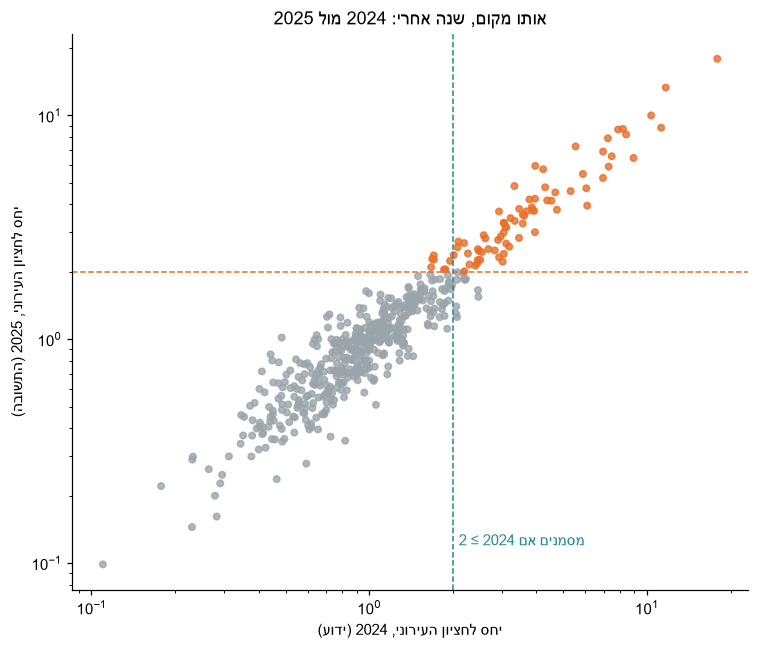

קורלציה בין היחס של 2024 ליחס של 2025: 0.974


In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
c = df.high_risk_2025.map({0: GREY, 1: ORANGE})
ax.scatter(df.ratio_2024, df.ratio_2025, c=c, s=18, alpha=.8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.axhline(2, color=ORANGE, ls='--', lw=1); ax.axvline(2, color=TEAL, ls='--', lw=1)
ax.set_xlabel(he('יחס לחציון העירוני, 2024 (ידוע)')); ax.set_ylabel(he('יחס לחציון העירוני, 2025 (התשובה)'))
ax.set_title(he('אותו מקום, שנה אחרי: 2024 מול 2025'))
ax.text(2.1, 0.12, he('מסמנים אם 2024 ≥ 2'), color=TEAL)
plt.tight_layout(); plt.show()
print('קורלציה בין היחס של 2024 ליחס של 2025:', round(df.ratio_2024.corr(df.ratio_2025), 3))

<div dir="rtl">

**מה רואים:** הנקודות יושבות כמעט על קו ישר (r ≈ 0.97). אזור שהיה פי 2 מהחציון ב־2024 נשאר כמעט תמיד מעל פי 2 ב־2025. **זה הסיגנל המרכזי: הפשיעה מתרכזת באותם מקומות משנה לשנה.**

</div>

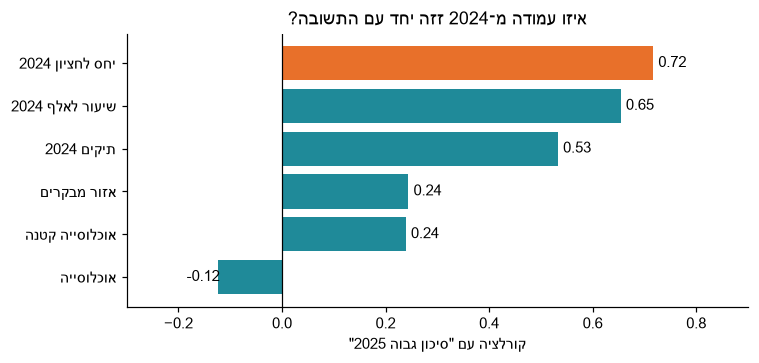

In [12]:
feat = ['pop', 'cases_2024', 'rate_2024', 'ratio_2024', 'is_visitor_area', 'is_small_pop']
corr_y = df[feat + ['high_risk_2025']].corr()['high_risk_2025'].drop('high_risk_2025').sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh([he(HE[i]) for i in corr_y.index], corr_y.values,
        color=[ORANGE if v == corr_y.max() else TEAL for v in corr_y.values])
for i, v in enumerate(corr_y.values):
    ax.text(v + (0.01 if v >= 0 else -0.06), i, f'{v:.2f}', va='center')
ax.axvline(0, color='black', lw=.8); ax.set_xlim(-0.3, 0.9)
ax.set_xlabel(he('קורלציה עם "סיכון גבוה 2025"')); ax.set_title(he('איזו עמודה מ־2024 זזה יחד עם התשובה?'))
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה רואים:** "יחס לחציון 2024" היא העמודה החזקה ביותר (0.72), אחריה השיעור לאלף ומספר התיקים ב־2024. דגלי אזור המבקרים והאוכלוסייה הקטנה תורמים סיגנל בינוני (0.24), ולגודל האוכלוסייה יש קשר שלילי חלש. **ההשערה מסעיף 5 בתוכנית אוששה.**

</div>

<div dir="rtl">

## 6. זוגות עמודות שמספרות את אותו סיפור

</div>

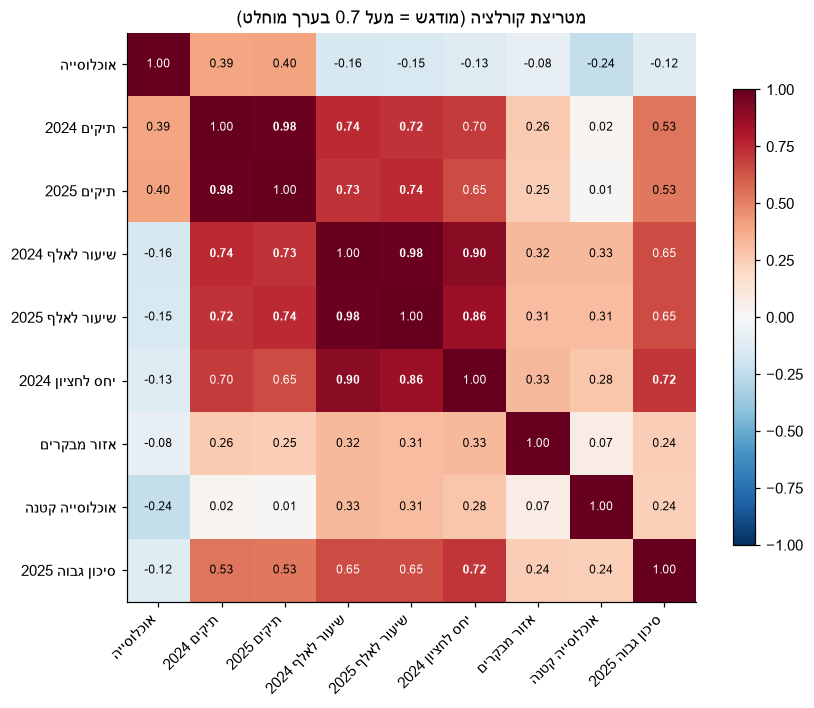

,עמודה א,עמודה ב,קורלציה
0,תיקים 2024,תיקים 2025,0.98
1,תיקים 2024,שיעור לאלף 2024,0.74
2,תיקים 2024,שיעור לאלף 2025,0.72
3,תיקים 2025,שיעור לאלף 2024,0.73
4,תיקים 2025,שיעור לאלף 2025,0.74
5,שיעור לאלף 2024,שיעור לאלף 2025,0.98
6,שיעור לאלף 2024,יחס לחציון 2024,0.90
7,שיעור לאלף 2025,יחס לחציון 2024,0.86
8,יחס לחציון 2024,סיכון גבוה 2025,0.72


In [13]:
num = ['pop', 'cases_2024', 'cases_2025', 'rate_2024', 'rate_2025', 'ratio_2024', 'is_visitor_area', 'is_small_pop', 'high_risk_2025']
M = df[num].corr()
labels = [he(HE[n]) for n in num]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(len(num))); ax.set_yticklabels(labels)
for i in range(len(num)):
    for j in range(len(num)):
        v = M.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > .6 else 'black', fontweight='bold' if (abs(v) > .7 and i != j) else 'normal')
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title(he('מטריצת קורלציה (מודגש = מעל 0.7 בערך מוחלט)'))
plt.tight_layout(); plt.show()

pairs = [(HE[a], HE[b], round(M.loc[a, b], 2)) for i, a in enumerate(num) for b in num[i + 1:] if abs(M.loc[a, b]) > .7]
pd.DataFrame(pairs, columns=['עמודה א', 'עמודה ב', 'קורלציה'])

<div dir="rtl">

**מה רואים:** "תיקים 2024" ו"תיקים 2025" כמעט זהות (0.98), כי מספר התיקים נקבע בעיקר לפי גודל האזור. **זו הסיבה שעובדים עם שיעור לתושב ולא עם ספירה.** גם "שיעור לאלף 2024" ו"יחס לחציון 2024" מספרות את אותו סיפור (0.90), ולכן נשאיר במודל רק את היחס לחציון.

</div>

<div dir="rtl">

## 7. סוג המשימה והמדד: איך נדע שאנחנו קרובים

</div>

In [14]:
y = df.high_risk_2025


def scores(pred, name):
    tp = ((pred == 1) & (y == 1)).sum()
    return {'מודל': name, 'אזורים שסומנו': int(pred.sum()), 'דיוק (accuracy)': (pred == y).mean(),
            'כמה מצאנו (recall)': tp / y.sum(), 'כמה צדקנו (precision)': tp / pred.sum() if pred.sum() else np.nan}


rows = [scores(pd.Series(0, index=df.index), 'תמיד "לא"')]
for t in [1.5, 1.75, 2.0, 2.5]:
    rows.append(scores((df.ratio_2024 >= t).astype(int), f'התמדה: יחס 2024 ≥ {t}'))
res = pd.DataFrame(rows).set_index('מודל').round(3)
res

,אזורים שסומנו,דיוק (accuracy),כמה מצאנו (recall),כמה צדקנו (precision)
מודל,,,,
"תמיד ""לא""",0,0.853,0.000,NaN
התמדה: יחס 2024 ≥ 1.5,131,0.900,1.000,0.595
התמדה: יחס 2024 ≥ 1.75,102,0.940,0.949,0.725
התמדה: יחס 2024 ≥ 2.0,82,0.966,0.910,0.866
התמדה: יחס 2024 ≥ 2.5,59,0.964,0.756,1.000


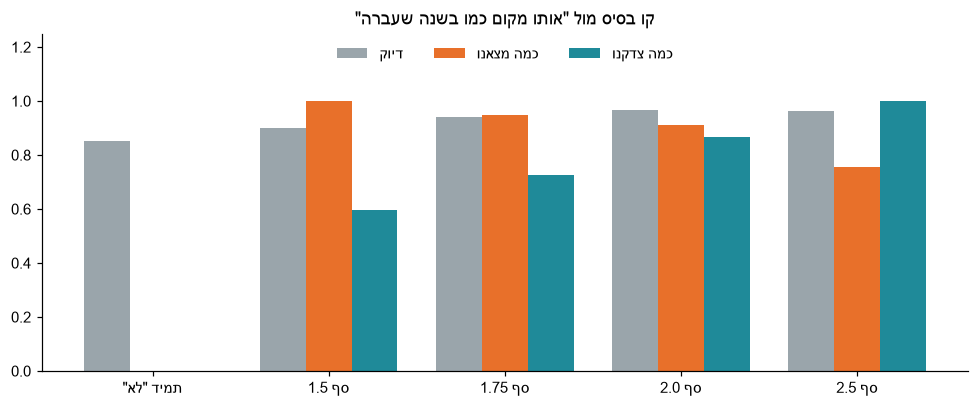

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
r = res.drop(columns='אזורים שסומנו')
x = np.arange(len(r)); w = .26
for k, (m, col, lab) in enumerate(zip(r.columns, [GREY, ORANGE, TEAL], ['דיוק', 'כמה מצאנו', 'כמה צדקנו'])):
    ax.bar(x + (k - 1) * w, r[m].fillna(0), w, label=he(lab), color=col)
ax.set_xticks(x); ax.set_xticklabels([he(i.replace('התמדה: יחס 2024 ≥ ', 'סף ')) for i in r.index])
ax.set_ylim(0, 1.25); ax.legend(ncol=3, loc='upper center', frameon=False)
ax.set_title(he('קו בסיס מול "אותו מקום כמו בשנה שעברה"'))
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה רואים:** "תמיד לא" מקבל דיוק של 85% ולא מוצא אף אזור מסוכן (recall = 0). **זו מלכודת הדיוק.** כלל ההתמדה בסף 2 מוצא 91% מהאזורים המסוכנים (recall), ו־87% מהאזורים שהוא מסמן באמת מסוכנים (precision). הורדת הסף ל־1.5 מוצאת את כולם, אבל עם יותר התראות שווא.

</div>

<div dir="rtl">

## סיכום

**יש סיגנל, והוא חזק.** שיעור הפשיעה של אזור ב־2024, יחסית לחציון העירוני, מנבא אם האזור יהיה בסיכון גבוה ב־2025, עם recall של 0.91 ו־precision של 0.87, הרבה מעל קו הבסיס של "תמיד לא". זה מצדיק את הגישה של LifeGuard לבנות את שכבת הסיכון מנתוני העבר: בשנת 2026 האפליקציה מפעילה את אותו כלל על נתוני 2025.

**הסתייגויות:**
- רק 2 שנים ו־530 אזורים ב־10 ערים. זו בדיקה של שנה אחת קדימה, ולא הוכחה ליציבות לאורך זמן.
- השיעור הוא לפי **תושבים**. באזורי מבקרים (מע"ר, שווקים) הוא מנופח, ושם הסיכון בפועל למבקר יכול להיות שונה.
- 47% מהאזורים נפלו בגלל נתונים חסרים. השכבה לא יודעת דבר עליהם, ואסור להציג אותם למשתמש כ"בטוחים".

</div>